<a href="https://colab.research.google.com/github/CLive31/Market-trend-sentinel/blob/main/market_trend_sentinel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
#Install dependencies
!pip install -q yfinance pandas requests
!pip install -q yfinance pandas requests matplotlib

 FINANCIAL TREND SCANNER & VISUALIZER | Run Date: 2026-11-01


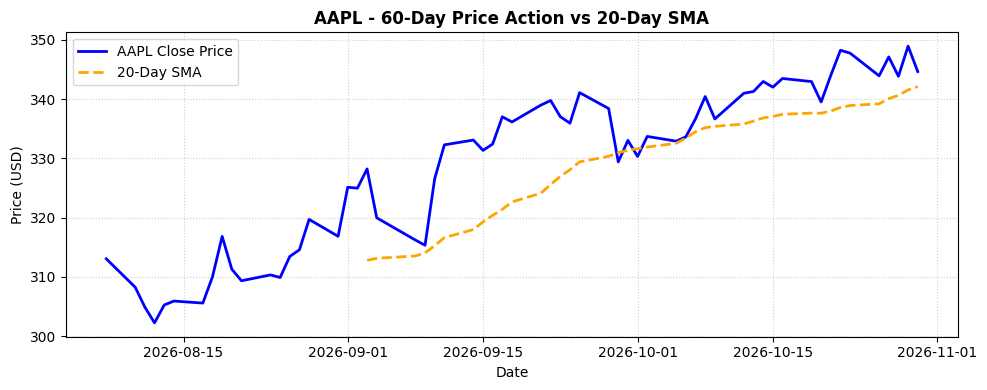

-----------------------------------------------------------------


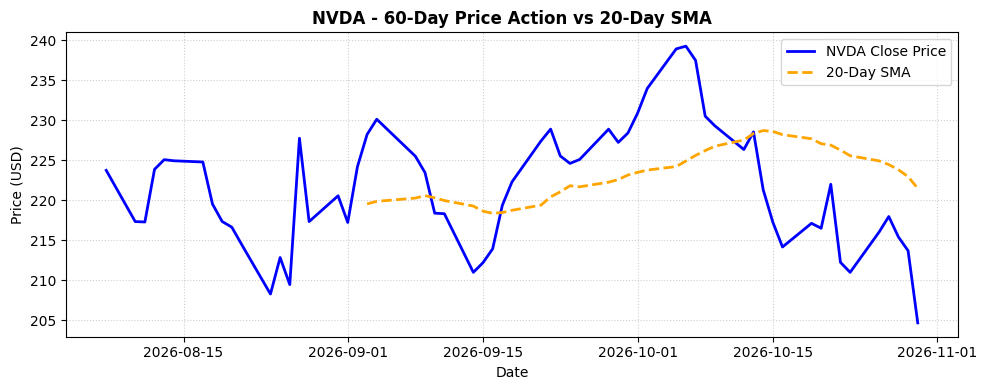

-----------------------------------------------------------------


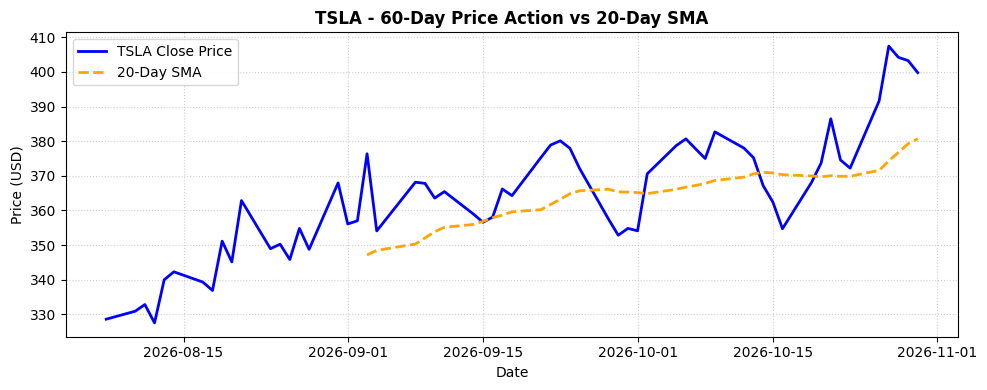

-----------------------------------------------------------------


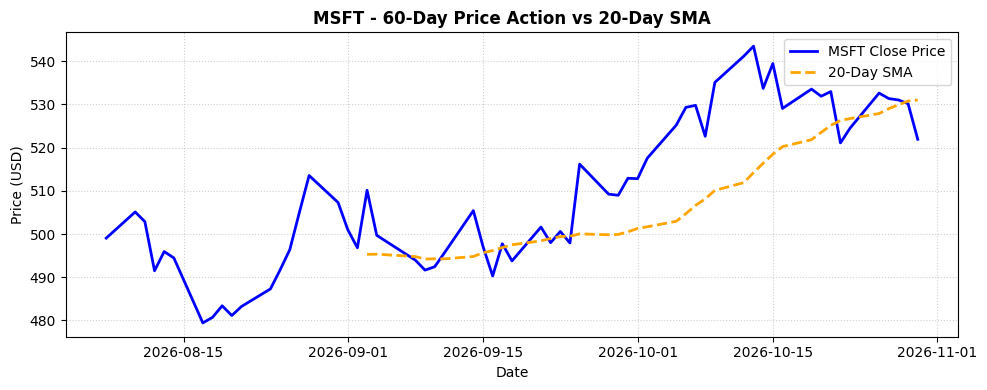

-----------------------------------------------------------------


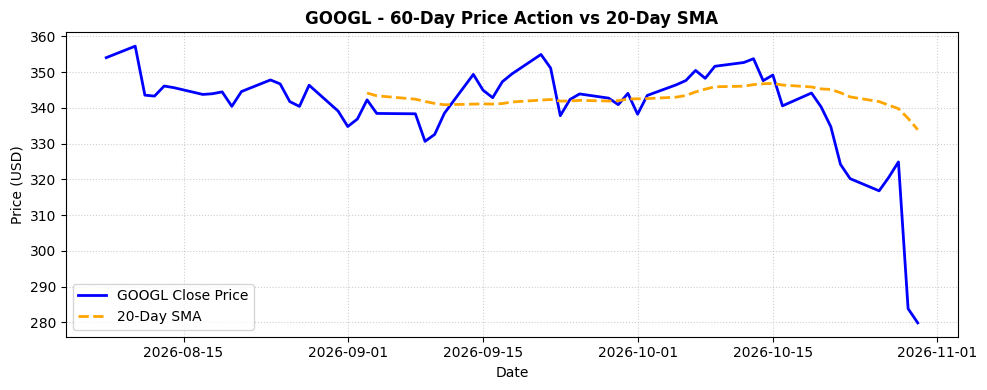

-----------------------------------------------------------------

SUMMARY TABLE:


,Ticker,Price ($),20-Day SMA ($),RSI (14),Signal Status
0,AAPL,344.63,342.08,54.9,🚀 BULLISH BREAKOUT
1,NVDA,204.64,221.46,31.0,⚖️ NEUTRAL / CONSOLIDATING
2,TSLA,399.81,380.70,59.7,🚀 BULLISH BREAKOUT
3,MSFT,521.91,530.98,36.2,⚖️ NEUTRAL / CONSOLIDATING
4,GOOGL,279.84,333.91,14.1,💡 OVERSOLD (Potential Rebound)


In [4]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import datetime

# Configuration: Select assets to track
TICKERS = ["AAPL", "NVDA", "TSLA", "MSFT", "GOOGL"]

def calculate_rsi(data, window=14):
    """Calculates Relative Strength Index (RSI) using pandas."""
    delta = data['Close'].diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=window).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=window).mean()
    rs = gain / loss
    rsi = 100 - (100 / (1 + rs))
    return rsi

def run_market_scanner_with_charts():
    print("="*65)
    print(f" FINANCIAL TREND SCANNER & VISUALIZER | Run Date: {datetime.date.today()}")
    print("="*65)

    results = []

    for ticker in TICKERS:
        # Fetch last 60 days of historical data
        df = yf.Ticker(ticker).history(period="60d")
        if df.empty:
            continue

        # Compute 20-day Simple Moving Average & 14-day RSI
        df['SMA_20'] = df['Close'].rolling(window=20).mean()
        df['RSI'] = calculate_rsi(df)

        latest_close = df['Close'].iloc[-1]
        latest_sma = df['SMA_20'].iloc[-1]
        latest_rsi = df['RSI'].iloc[-1]

        # Determine signal status
        if latest_close > latest_sma and latest_rsi < 70:
            status = "🚀 BULLISH BREAKOUT"
        elif latest_rsi > 70:
            status = "⚠️ OVERBOUGHT (High Risk)"
        elif latest_rsi < 30:
            status = "💡 OVERSOLD (Potential Rebound)"
        else:
            status = "⚖️ NEUTRAL / CONSOLIDATING"

        results.append({
            "Ticker": ticker,
            "Price ($)": round(latest_close, 2),
            "20-Day SMA ($)": round(latest_sma, 2),
            "RSI (14)": round(latest_rsi, 1),
            "Signal Status": status
        })

        # --- MATPLOTLIB VISUALIZATION ---
        plt.figure(figsize=(10, 4))
        plt.plot(df.index, df['Close'], label=f'{ticker} Close Price', color='blue', linewidth=2)
        plt.plot(df.index, df['SMA_20'], label='20-Day SMA', color='orange', linestyle='--', linewidth=2)

        plt.title(f"{ticker} - 60-Day Price Action vs 20-Day SMA", fontsize=12, fontweight='bold')
        plt.xlabel("Date")
        plt.ylabel("Price (USD)")
        plt.legend(loc='best')
        plt.grid(True, linestyle=':', alpha=0.6)
        plt.tight_layout()
        plt.show()
        print("-" * 65)

    # Convert summary results into a clean tabular DataFrame for display
    summary_df = pd.DataFrame(results)
    print("\nSUMMARY TABLE:")
    display(summary_df)

if __name__ == "__main__":
    run_market_scanner_with_charts()